# Single layer — paired LDI ensembles: no energy bias, energy bias, energy bias and strain

What can be recovered from the same sparse geological observations, what does
the energy-biased training add, and what changes when finite-strain observations
are added? Three paired 20-member ensembles are fitted to the observations made by
`03a_single_layer_data`, with the basis and training settings tuned on a single
fit in `03b_single_layer_fit` (read from its `results/fit_settings.json`):

1. **No energy bias, geometry only:** sparse contact points, signed bedding
   normals, restored contact flatness and stratigraphic ordering. Raw cubic
   modes, every parameter trained by Adam from a small random start.
2. **Energy bias, geometry only:** the same constraints, with the
   energy-biased scheme of `01b` and `02b`: energy-normalised cubic modes,
   amplitudes started at zero and trained by SGD with (Nesterov) momentum,
   phase and bias trained by Adam.
3. **Energy bias, geometry plus strain:** as 2, with 25 of the 100 marker-cell
   strain ellipses added.

The same constraints and Fourier seeds are used throughout (member *k* has the
same seed in all three ensembles). There is no energy penalty in any of them.

**What this notebook is.** Computation and quick checks only; nothing drawn
here is saved. What is saved, to `results/`:

- `inputs.npz` — the evaluation grid axes, the strain display points and the
  origin;
- `ensemble_plain.npz`, `ensemble_geometry.npz`, `ensemble_strain.npz` — per
  member: lithology on the grid, the full digitised contacts pulled back through
  Φ⁻¹, and the unit-determinant strain shape tensor at the display points and at
  every marker cell;
- `summary.json` — every number quoted in the text: restored-horizon spread,
  bulk shortening and held-out strain errors;
- `fit_settings.json` — 03b's parameters plus the ensemble's seeds; `members.pt`
  — every member's fitted field parameters.

The figures are made in `03d_single_layer_figures.ipynb`.

## Setup

In [1]:
import json
from pathlib import Path
from time import perf_counter
import random

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import qmc
import torch

import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.geometry import Grid
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.training import SpectralWarmup

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import single_layer_inputs as sli  # benchmark, observation split and ensemble measures, shared with 03a, 03b and 03d

figstyle.apply()
curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = Path("results")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={curlew.device}, dtype={curlew.dtype}")

device=cpu, dtype=torch.float32


## Benchmark and observations

The ground truth and the observation split from 03a, in the frame shifted to
the mean of the digitised contacts; H0 is the uppermost contact.

In [2]:
truth = sli.load_truth()
obs = sli.load_observations(truth)
horizons_full, horizon_names = truth["horizons_full"], truth["horizon_names"]
horizons, gp, gv = obs["horizons"], obs["gp"], obs["gv"]
strain_xy = truth["strain_xy"]

iq_pairs = [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]
anchor = torch.tensor([0.0, 0.0], dtype=curlew.dtype, device=curlew.device)
print(f"contacts {sum(map(len, horizons))} | bedding {len(gp)} | "
      f"strain {len(obs['strain_train_idx'])} in the fit, {len(obs['strain_test_idx'])} held out")

contacts 60 | bedding 10 | strain 15 in the fit, 85 held out


## Evaluation grid and strain display points

A 4-unit grid over 1.15 times the extent of the contacts, and one shared
Poisson-disk sample (20-unit spacing) at which every member's strain is evaluated
for the strain panels.

In [3]:
pts = np.vstack(horizons_full)
extent = 1.15 * (pts.max(axis=0) - pts.min(axis=0))
G = Grid(tuple(extent), step=(4.0, 4.0), center=(0.0, 0.0), sampleArgs=dict(N=4096))
domaxes = G.tformed_axes
xlim = (float(domaxes[0].min()), float(domaxes[0].max()))
zlim = (float(domaxes[1].min()), float(domaxes[1].max()))
grid_tensor = torch.as_tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)


def poisson_points(bounds, spacing, seed):
    lower = np.array([bounds[0][0], bounds[1][0]], dtype=float)
    upper = np.array([bounds[0][1], bounds[1][1]], dtype=float)
    scale = float(np.max(upper - lower))
    unit = qmc.PoissonDisk(d=2, radius=spacing / scale, seed=seed).fill_space()
    points = lower + scale * unit
    return points[np.all(points < upper, axis=1)]


strain_sample_xy = poisson_points((xlim, zlim), spacing=20.0, seed=SEED + 7)
# Where the vertical marker lines cross the horizons: material points across the section,
# restored by every member for the spread of restored x (σx)
nodes_present, node_row, node_col = sli.grid_nodes(horizons_full, truth["verticals_full"])
np.savez_compressed(
    OUT_DIR / "inputs.npz",
    x=np.asarray(domaxes[0], dtype=float), z=np.asarray(domaxes[1], dtype=float),
    origin=truth["origin"], strain_sample_xy=strain_sample_xy,
    nodes_present=nodes_present, node_row=node_row, node_col=node_col,
)
print(f"grid {G.shape}, {len(strain_sample_xy)} strain display points; wrote {OUT_DIR / 'inputs.npz'}")

grid (149, 135), 487 strain display points; wrote results/inputs.npz


## Paired ensembles

Every member uses a different fixed random Fourier basis but the same data
and architecture (the optimiser differs only for the no-energy-bias ensemble); member *k* has the same seed in both ensembles.
The velocity is divergence-free by construction and its integration gives a
volume-preserving diffeomorphism.

The strain observations constrain the shape of the local spatial strain
ellipse after isotropic scale is removed; reversing an observed eigenvector
leaves the loss unchanged.

In [4]:
# The basis and training settings are 03b's, where they are tuned on a single fit; only the
# ensemble's own settings are set here.
P = json.loads((OUT_DIR / "fit_settings.json").read_text())   # written by 03b_single_layer_fit
N_ENSEMBLE = 15
N_DIRECTIONS, MODES_PER_OCTAVE = P["n_directions"], P["modes_per_octave"]
LENGTH_SCALE_RANGE, N_FEATURES, BAND_INFO = tuple(P["length_scale_range"]), P["n_features"], P["band_info"]
N_STEPS, INTEGRATOR, EPOCHS = P["n_steps"], P["integrator"], P["epochs"]
WEIGHTS, STRAIN_WEIGHT, IQ_SAMPLES = P["weights"], P["strain_weight"], P["iq_samples"]
LR_ADAM, LR_SGD, AMP_MOMENTUM, INIT_STD = P["lr_adam"], P["lr_sgd"], P["amp_momentum"], P["init_std"]
LR_PLAIN, INIT_STD_PLAIN = P["lr_plain"], P["init_std_plain"]   # the no-energy-bias ensemble
ENERGY_NORMALISED = P["energy_normalised"]
print(f"from 03b: band {LENGTH_SCALE_RANGE[0]:.0f}-{LENGTH_SCALE_RANGE[1]:.0f} | M {N_FEATURES} | "
      f"{N_DIRECTIONS} directions | {EPOCHS} epochs")

ENSEMBLE_SEEDS = np.random.default_rng(SEED + 91).integers(0, 2**31 - 1, size=N_ENSEMBLE, dtype=np.int64)
print(f"paired ensemble seeds: {ENSEMBLE_SEEDS.tolist()}")


KINDS = ("plain", "geometry", "strain")   # no energy bias | energy bias | energy bias + strain
LABELS = {"plain": "no energy bias", "geometry": "energy bias", "strain": "energy bias + strain"}


def constraint_set(include_strain):
    kwargs = dict(gp=gp, gv=gv, eq=horizons, iq=(IQ_SAMPLES, iq_pairs))
    if include_strain:
        kwargs.update(sp=obs["sp"], se=obs["se"], sr=obs["sr"])
    return CSet(**kwargs)


def fit_member(seed, member, kind):
    biased = kind != "plain"
    velocity = euler_velocity(
        2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=LENGTH_SCALE_RANGE,
        stream="alpha", activation="cubic", seed=int(seed), energy_normalised=ENERGY_NORMALISED and biased,
    )
    if biased:
        init_std, lr = INIT_STD, LR_ADAM
        optimizer = {
            "amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
            "shape": (torch.optim.Adam, dict(lr=LR_ADAM)),
        }
    else:
        init_std, lr, optimizer = INIT_STD_PLAIN, LR_PLAIN, None   # Adam on everything
    include_strain = kind == "strain"
    event = restore(
        f"single_layer_{kind}_{member:02d}",
        C=constraint_set(include_strain),
        H=HSet.restore(**WEIGHTS, strain_loss=STRAIN_WEIGHT if include_strain else 0),
        velocity=velocity, n_steps=N_STEPS, depth_axis=1, integrator=INTEGRATOR,
        init_std=init_std, sigma_floor=0.0, signed_normals=True, learning_rate=lr,
        optimizer=optimizer, pin=anchor,
    )
    for hi, trace in enumerate(reversed(horizons)):
        event.addIsosurface(f"horizon_{hi}", seed=trace)
    model = curlew.GeoModel([event])
    if P.get("spectral_warmup") and biased:        # as in 03b: octaves opened longest first
        with SpectralWarmup(event) as schedule:
            model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True, schedule=schedule)
    else:
        model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True)
    return model, event.field

from 03b: band 570-2854 | M 160 | 32 directions | 2500 epochs
paired ensemble seeds: [35034316, 1318916082, 1609356072, 1813334947, 43736948, 1380621865, 210014305, 1258900537, 1656886435, 984003558, 761171587, 1174349671, 1914556445, 16222087, 196147228]


### Evaluation of each member

- **lithology** on the grid;
- **restored contacts**: the full digitised contacts pulled back through Φ⁻¹,
  and the crossings of the vertical marker lines with the horizons;
- **strain shape**: the spatial tensor B = F Fᵀ with F = (DΦ⁻¹)⁻¹, scaled to
  unit determinant, at the display points and at every marker cell.

In [5]:
def strain_shape(field, points):
    pts_t = torch.as_tensor(points, dtype=curlew.dtype, device=curlew.device)
    with torch.no_grad():
        _x0, J = field.total_inverse_map_with_jacobian(pts_t)
        F_map = torch.linalg.inv(J)
        B = F_map @ F_map.transpose(-1, -2)
        B = B / torch.linalg.det(B).clamp_min(1e-12).sqrt()[:, None, None]
    return B.cpu().numpy()


def evaluate_member(model, field):
    with torch.no_grad():
        litho = np.asarray(G.reshape(model.predict(grid_tensor, litho=True).lithoID))
        restored = np.stack([
            field.total_inverse_map(torch.as_tensor(trace, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
            for trace in horizons_full
        ])
        nodes_restored = field.total_inverse_map(
            torch.as_tensor(nodes_present, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
    return dict(lithology=litho.astype(np.int8), restored=restored, nodes_restored=nodes_restored,
                B_display=strain_shape(field, strain_sample_xy), B_cells=strain_shape(field, strain_xy))


def fit_ensemble(kind):
    label = LABELS[kind]
    runs, states = [], []
    t0 = perf_counter()
    for member, seed in enumerate(ENSEMBLE_SEEDS, start=1):
        model, field = fit_member(seed, member, kind)
        runs.append(evaluate_member(model, field))
        states.append({k: v.detach().cpu() for k, v in field.state_dict().items()})
        print(f"{label}: member {member:02d}/{N_ENSEMBLE}, seed={int(seed)} fitted")
    print(f"{label}: {perf_counter() - t0:.1f} s")
    return {k: np.stack([r[k] for r in runs]) for k in runs[0]}, states

In [6]:
ens_plain, states_plain = fit_ensemble("plain")

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


no energy bias: member 01/15, seed=35034316 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


no energy bias: member 02/15, seed=1318916082 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


no energy bias: member 03/15, seed=1609356072 fitted


... (20 outputs left out)

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


no energy bias: member 14/15, seed=16222087 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


no energy bias: member 15/15, seed=196147228 fitted
no energy bias: 218.6 s


In [7]:
ens_geometry, states_geometry = fit_ensemble("geometry")

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias: member 01/15, seed=35034316 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias: member 02/15, seed=1318916082 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias: member 03/15, seed=1609356072 fitted


... (20 outputs left out)

L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias: member 14/15, seed=16222087 fitted


L=0.000 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias: member 15/15, seed=196147228 fitted
energy bias: 251.0 s


In [8]:
ens_strain, states_strain = fit_ensemble("strain")

L=0.002 grad_loss=0.001 strain_loss=0.001 eq_loss=0.000: : 2500/2500|


energy bias + strain: member 01/15, seed=35034316 fitted


L=0.001 grad_loss=0.000 strain_loss=0.000 eq_loss=0.001: : 2500/2500|


energy bias + strain: member 02/15, seed=1318916082 fitted


L=0.001 grad_loss=0.000 strain_loss=0.001 eq_loss=0.000: : 2500/2500|


energy bias + strain: member 03/15, seed=1609356072 fitted


... (20 outputs left out)

L=0.001 grad_loss=0.000 strain_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias + strain: member 14/15, seed=16222087 fitted


L=0.001 grad_loss=0.000 strain_loss=0.000 eq_loss=0.000: : 2500/2500|


energy bias + strain: member 15/15, seed=196147228 fitted
energy bias + strain: 359.5 s


## Numbers quoted in the text

- **Restored-horizon spread**: σ*x*, the ensemble standard deviation of the
  restored *x* of the vertical marker lines where they cross each horizon (rms
  over the 21 verticals), and σ*z*, that of the mean restored depth;
- **bulk shortening** $1 - W_\mathrm{present}/W_\mathrm{restored}$ and
  $S = (W_\mathrm{restored}/W_\mathrm{present})^2$ from the horizon chords,
  for the matrix grid lines (H0, H1, H4, H5), the competent layer (H2, H3) and
  all horizons; Hudleston's Fig. 3A has $S = 6$;
- **held-out strain**: per member, over the 75 held-out cells, the RMSE in log
  stretch ratio, the median major-axis error (0–90°) and the RMSE of the
  unit-determinant shape tensor.

In [9]:
def mean_sd(a):
    a = np.asarray(a, dtype=float)
    return {"mean": float(a.mean()), "sd": float(a.std())}


summary = {"hudleston_S": sli.HUDLESTON_S, "horizons": horizon_names}
for key, ens in (("plain", ens_plain), ("geometry", ens_geometry), ("strain", ens_strain)):
    spread = sli.restored_horizon_spread(ens["restored"])
    bulk = sli.bulk_shortening(horizons_full, ens["restored"])
    held = sli.heldout_metrics(ens["B_cells"], truth, obs["strain_test_idx"])
    groups = {"matrix": sli.MATRIX, "competent": sli.COMPETENT, "all": tuple(range(len(horizon_names)))}
    summary[key] = {
        "sigma_x": sli.restored_vertical_spread(ens["nodes_restored"], node_row).tolist(),
        "sigma_z": spread["sigma_z"].tolist(),
        "flatness": mean_sd(spread["flatness"]),
        "bulk": {g: {"shortening": mean_sd(bulk["shortening"][:, list(idx)]), "S": mean_sd(bulk["S"][:, list(idx)])}
                 for g, idx in groups.items()},
        "heldout": {name: mean_sd(v) for name, v in held.items()},
    }

for key, label in LABELS.items():
    s = summary[key]
    print(f"{label}:")
    print(f"  sigma_x {np.round(s['sigma_x'], 1).tolist()} | sigma_z {np.round(s['sigma_z'], 1).tolist()} (model units)")
    for g, b in s["bulk"].items():
        print(f"  {g:9s} shortening {100 * b['shortening']['mean']:.0f} ± {100 * b['shortening']['sd']:.0f}%, "
              f"S = {b['S']['mean']:.1f} ± {b['S']['sd']:.1f}")
    for name, v in s["heldout"].items():
        print(f"  {name:22s} {v['mean']:.3f} ± {v['sd']:.3f}")

no energy bias:
  sigma_x [121.4, 58.6, 65.9, 78.2, 87.1, 137.3] | sigma_z [13.0, 2.6, 1.5, 4.9, 8.9, 17.5] (model units)
  matrix    shortening 46 ± 12%, S = 4.0 ± 2.1
  competent shortening 60 ± 6%, S = 6.7 ± 2.7
  all       shortening 50 ± 12%, S = 4.9 ± 2.6
  log stretch RMSE       0.936 ± 0.230
  axis error (degrees)   18.676 ± 2.319
  shape-tensor RMSE      2.734 ± 1.471
energy bias:
  sigma_x [18.6, 8.2, 8.0, 12.8, 17.4, 26.0] | sigma_z [3.3, 1.1, 0.5, 1.3, 2.7, 5.6] (model units)
  matrix    shortening 27 ± 10%, S = 2.0 ± 0.5
  competent shortening 41 ± 2%, S = 2.9 ± 0.2
  all       shortening 31 ± 11%, S = 2.3 ± 0.6
  log stretch RMSE       0.759 ± 0.021
  axis error (degrees)   15.115 ± 1.552
  shape-tensor RMSE      1.485 ± 0.032
energy bias + strain:
  sigma_x [13.0, 6.8, 5.3, 6.4, 7.5, 10.3] | sigma_z [1.3, 0.9, 0.9, 0.9, 1.0, 1.6] (model units)
  matrix    shortening 49 ± 2%, S = 3.9 ± 0.2
  competent shortening 50 ± 1%, S = 4.0 ± 0.1
  all       shortening 50 ± 1%, S = 4

## Quick check

Lithology entropy of each ensemble (not saved).

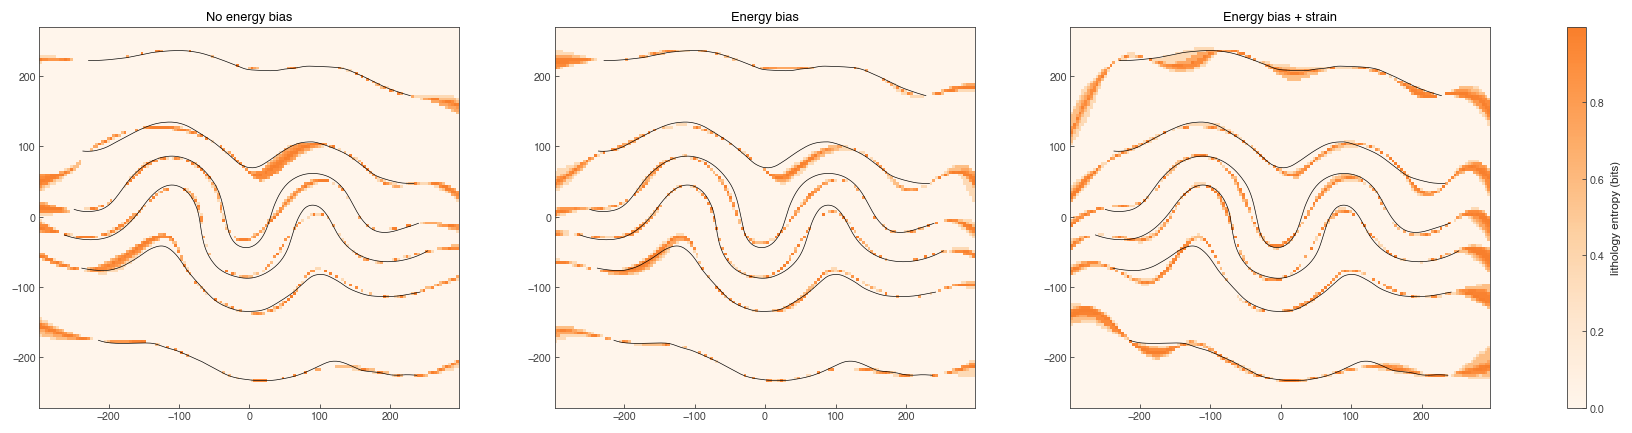

In [10]:
classes = np.unique(np.concatenate([e["lithology"].ravel() for e in (ens_plain, ens_geometry, ens_strain)]))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5), constrained_layout=True)
for ax, (label, ens) in zip(axs, (("No energy bias", ens_plain), ("Energy bias", ens_geometry), ("Energy bias + strain", ens_strain))):
    im = ax.pcolormesh(domaxes[0], domaxes[1], sli.lithology_entropy(ens["lithology"], classes).T,
                       cmap=figstyle.entropy_cmap(), shading="auto")
    for trace in horizons_full:
        ax.plot(trace[:, 0], trace[:, 1], color="k", lw=0.4)
    ax.set_aspect("equal")
    ax.set_title(label)
fig.colorbar(im, ax=axs, label="lithology entropy (bits)")
plt.show()

## Save

In [11]:
for key, ens in (("plain", ens_plain), ("geometry", ens_geometry), ("strain", ens_strain)):
    np.savez_compressed(OUT_DIR / f"ensemble_{key}.npz", seeds=ENSEMBLE_SEEDS, **ens)
torch.save({"plain": states_plain, "geometry": states_geometry, "strain": states_strain}, OUT_DIR / "members.pt")
(OUT_DIR / "summary.json").write_text(json.dumps(summary, indent=1))
# 03b's settings, plus the ensemble's own
(OUT_DIR / "fit_settings.json").write_text(json.dumps(
    {**P, "seed": SEED, "n_ensemble": N_ENSEMBLE, "ensemble_seeds": ENSEMBLE_SEEDS.tolist()}, indent=2))
for f in sorted(OUT_DIR.iterdir()):
    print(f"wrote {f}  ({f.stat().st_size / 1e6:.2f} MB)")

wrote results/ensemble_geometry.npz  (0.39 MB)
wrote results/ensemble_plain.npz  (0.39 MB)
wrote results/ensemble_strain.npz  (0.39 MB)
wrote results/fit_settings.json  (0.00 MB)
wrote results/inputs.npz  (0.01 MB)
wrote results/members.pt  (0.46 MB)
wrote results/summary.json  (0.00 MB)
